# Numerical Solvers, Finite Differences, and Automatic Differentiation

**AI Mathematics · 4. Numerical Computation**

Compare iterative numerical methods with finite differences and automatic differentiation as used in modern deep learning.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Use a simple iterative method to solve an equation.
- Estimate derivatives with finite differences.
- Explain how automatic differentiation applies the chain rule.

In [1]:
import numpy as np

## 1. Iterative solution of an equation
An iterative method starts from a guess and repeatedly updates it. Convergence depends on the method and problem. A fixed number of iterations does not guarantee that a correct solution has been found, so monitor residuals or stopping criteria.

In [2]:
def newton_sqrt(value, tol=1e-12, max_iter=100):
    if value < 0:
        raise ValueError("This real-valued example requires value >= 0")
    if value == 0:
        return 0.0
    x = value if value >= 1 else 1.0
    for _ in range(max_iter):
        next_x = 0.5 * (x + value / x)
        if abs(next_x - x) <= tol * max(1.0, abs(next_x)):
            return next_x
        x = next_x
    raise RuntimeError("Newton iteration did not converge")

print(newton_sqrt(2.0), np.sqrt(2.0))

1.414213562373095 1.4142135623730951


## 2. Finite-difference derivatives
Forward differences use \([f(x+h)-f(x)]/h\); central differences use \([f(x+h)-f(x-h)]/(2h)\). Central differences are often more accurate for smooth functions but need two evaluations and can still suffer from rounding error.

In [3]:
def derivative_central(f, x, h=1e-5):
    return (f(x+h)-f(x-h))/(2*h)

f = lambda x: np.log(x)
x = 2.0
print("estimate:", derivative_central(f, x))
print("exact:", 1/x)

estimate: 0.5000000000088267
exact: 0.5


## 3. Numerical Jacobian
For small problems, perturb one input coordinate at a time to estimate each Jacobian column. This costs roughly two function evaluations per input dimension for central differences and becomes expensive for large neural networks.

In [4]:
def jacobian_fd(f, x, h=1e-5):
    x = np.asarray(x, dtype=float)
    y = np.atleast_1d(f(x))
    J = np.empty((y.size, x.size))
    for j in range(x.size):
        delta = np.zeros_like(x); delta[j] = h
        J[:, j] = (np.atleast_1d(f(x+delta))-np.atleast_1d(f(x-delta)))/(2*h)
    return J

f = lambda x: np.array([x[0]**2 + x[1], x[0]*x[1]])
print(jacobian_fd(f, [2.0, 3.0]))

[[4. 1.]
 [3. 2.]]


## 4. Automatic differentiation
Automatic differentiation (AD) decomposes a program into elementary operations and applies derivative rules along the computational graph. It is not the same as symbolic algebra or finite differences. Reverse-mode AD is efficient for scalar losses with many parameters; forward mode can be attractive when there are few inputs and many outputs.

In [5]:
# A hand-worked computational graph: L = (w*x + b - y)^2 / 2
w, x, b, y = 0.5, 2.0, 0.1, 1.5
z = w*x + b
e = z - y
L = 0.5 * e**2
dL_de = e
de_dz = 1.0
dz_dw = x
dL_dw = dL_de * de_dz * dz_dw
print("loss:", L, "dL/dw:", dL_dw)

# The same gradient can be checked numerically on this tiny example.
def loss_w(w_value):
    return 0.5 * (w_value*x + b - y)**2
h = 1e-6
print("finite difference:", (loss_w(w+h)-loss_w(w-h))/(2*h))

loss: 0.07999999999999996 dL/dw: -0.7999999999999998
finite difference: -0.8000000000230045


## 5. Solver diagnostics
For a root solver, inspect \(|f(x)|\); for a linear system, inspect \(\|Ax-b\|\); for an optimization algorithm, inspect loss and gradient norms. Tolerances should reflect scale and required accuracy. Avoid silently accepting a failed iteration.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: root finding and finite differences

Numerical methods trade exact symbolic answers for iterative approximations. Newton's method uses both a function value and derivative; it can converge quickly near a good initial guess, but may fail if the derivative is near zero or the starting point is poor. Always check the residual, not just the iteration count.

final root estimate: 1.414213562373095 residual: -4.440892098500626e-16


14_numerical_solvers_finite_differences_autodiff.ipynb:cell14:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,iteration,x,f(x)
0,0,1.000000,-1.000000
1,1,1.500000,0.250000
2,2,1.416667,0.006944
3,3,1.414216,0.000006
4,4,1.414214,0.000000
5,5,1.414214,0.000000
6,6,1.414214,-0.000000
7,7,1.414214,0.000000


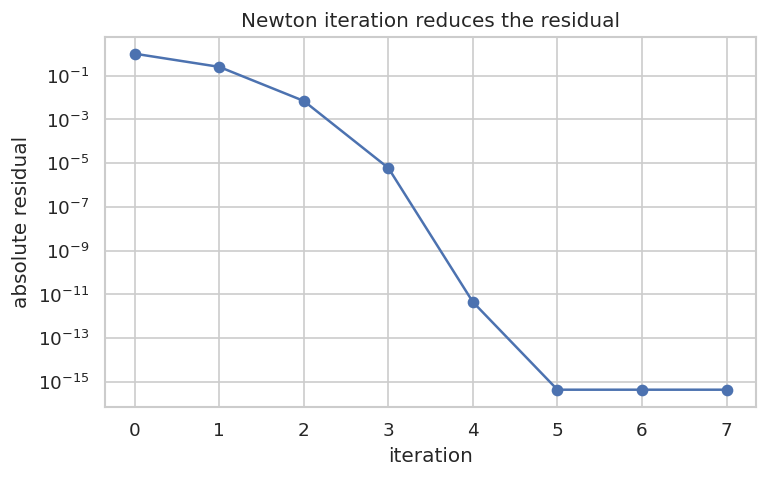

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_root_f(t): return t*t-2
def viz_root_df(t): return 2*t
viz_root_x = 1.0
viz_root_rows = []
for viz_root_i in range(8):
    viz_root_rows.append({"iteration": viz_root_i, "x": viz_root_x, "f(x)": viz_root_f(viz_root_x)})
    viz_root_x = viz_root_x-viz_root_f(viz_root_x)/viz_root_df(viz_root_x)
viz_root_df_table = pd.DataFrame(viz_root_rows)
display(viz_root_df_table.round(8))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_root_df_table["iteration"], np.abs(viz_root_df_table["f(x)"]), marker="o")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("absolute residual"); ax.set_title("Newton iteration reduces the residual"); plt.show()
print("final root estimate:", viz_root_x, "residual:", viz_root_f(viz_root_x))

### Finite-difference step size matters

Forward differences have first-order truncation error; central differences have second-order truncation error for sufficiently smooth functions. At extremely small steps, floating-point cancellation increases error. Automatic differentiation avoids finite-difference step selection by applying derivative rules to the computation graph, although it still uses floating-point arithmetic.

14_numerical_solvers_finite_differences_autodiff.ipynb:cell16:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,h,forward error,central error
0,1.000000e-01,3.345815e-02,1.274100e-03
1,1.000000e-02,3.233809e-03,1.274731e-05
2,1.000000e-03,3.222363e-04,1.274740e-07
3,1.000000e-04,3.221216e-05,1.275000e-09
4,1.000000e-05,3.221102e-06,1.700000e-11
5,1.000000e-06,3.221090e-07,2.200000e-11
6,1.000000e-07,3.211900e-08,7.700000e-11
7,1.000000e-08,2.298000e-09,2.298000e-09
8,1.000000e-09,2.298000e-09,2.298000e-09
9,1.000000e-10,4.463870e-07,4.463870e-07


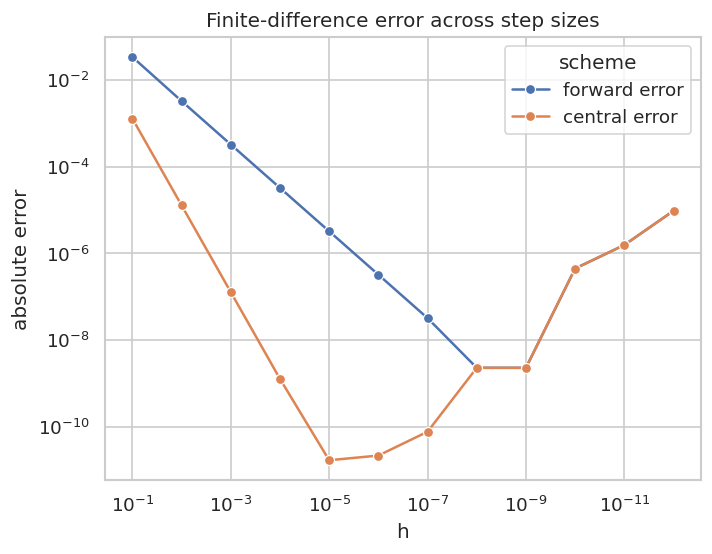

In [7]:
viz_fd_x0 = 0.7
viz_fd_exact = np.cos(viz_fd_x0)
viz_fd_h = np.logspace(-1, -12, 12)
viz_fd_forward = (np.sin(viz_fd_x0+viz_fd_h)-np.sin(viz_fd_x0))/viz_fd_h
viz_fd_central = (np.sin(viz_fd_x0+viz_fd_h)-np.sin(viz_fd_x0-viz_fd_h))/(2*viz_fd_h)
viz_fd_df = pd.DataFrame({"h": viz_fd_h, "forward error": np.abs(viz_fd_forward-viz_fd_exact), "central error": np.abs(viz_fd_central-viz_fd_exact)})
display(viz_fd_df.round(12))
sns.lineplot(data=viz_fd_df.melt(id_vars="h", var_name="scheme", value_name="absolute error"), x="h", y="absolute error", hue="scheme", marker="o")
plt.xscale("log"); plt.yscale("log"); plt.gca().invert_xaxis(); plt.title("Finite-difference error across step sizes"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Use Newton’s method to solve x^2 - 9 = 0 starting at x=2.

In [8]:
x = 2.0
for _ in range(20):
    x = x - (x*x - 9)/(2*x)
print(x)

3.0


### Exercise 2
Exercise 2: Estimate the derivative of cos(x) at x=1.

In [9]:
h = 1e-5
x = 1.0
print((np.cos(x+h)-np.cos(x-h))/(2*h), "exact:", -np.sin(x))

-0.8414709847970324 exact: -0.8414709848078965


## Key takeaways
- Iterative methods need sensible initialization and stopping criteria.
- Finite differences are helpful for testing derivatives but expensive in high dimensions.
- Automatic differentiation applies the chain rule to the computational graph, which powers neural-network training.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.